## Лабораторная работа №1 | Вариант 5

Выполнил: 

**Запуск:** Python 3.10+ с библиотеками из `requirements.txt`; выполнить
все ячейки сверху вниз. `data.csv` должен лежать рядом с ноутбуком
(также поддерживается запуск из корня репозитория).

### 1. Numpy

In [ ]:
import numpy as np

rng = np.random.default_rng(42)

1. Создайте единичную матрицу размером 3х3

In [2]:
identity_matrix = np.eye(3, dtype=int)
identity_matrix

array([[1, 0, 0],
       [0, 1, 0],
       [0, 0, 1]])

2. Создайте кастомный dtype который описывает цвет состоящий из 4х unsigned bytes(RGBA пиксель)

In [3]:
rgba_dtype = np.dtype([
    ("r", np.uint8), ("g", np.uint8),
    ("b", np.uint8), ("a", np.uint8),
])
pixel = np.array((255, 128, 0, 255), dtype=rgba_dtype)
print("Тип:", rgba_dtype)
print("Размер пикселя:", rgba_dtype.itemsize, "байта")
print("RGBA:", pixel)

Тип: [('r', 'u1'), ('g', 'u1'), ('b', 'u1'), ('a', 'u1')]
Размер пикселя: 4 байта
RGBA: (255, 128, 0, 255)


3. Как игнорировать все numpy warnings(не рекомендуем к использованию)?

In [ ]:
import warnings

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    with np.errstate(all="ignore"):
        warning_example = np.array([1.0, 0.0]) / 0.0

print(warning_example)

[inf nan]


4. Создайте случайный вектор размера 10 и отсортируйте его

In [5]:
random_vector = rng.random(10)
sorted_vector = np.sort(random_vector)
print("Исходный вектор:", random_vector)
print("Отсортированный:", sorted_vector)

Исходный вектор: [0.77395605 0.43887844 0.85859792 0.69736803 0.09417735 0.97562235
 0.7611397  0.78606431 0.12811363 0.45038594]
Отсортированный: [0.09417735 0.12811363 0.43887844 0.45038594 0.69736803 0.7611397
 0.77395605 0.78606431 0.85859792 0.97562235]


5. Создайте read-only массив(неизменяемый)

In [6]:
readonly_array = np.arange(10)
readonly_array.setflags(write=False)
print(readonly_array)
print("Запись разрешена:", readonly_array.flags.writeable)
try:
    readonly_array[0] = -1
except ValueError as error:
    print("Попытка записи:", error)

[0 1 2 3 4 5 6 7 8 9]
Запись разрешена: False
Попытка записи: assignment destination is read-only


6. Рассмотрим случайную матрицу размером 10х2, представляющую декартовы координаты, преобразуем их в полярные координаты

In [7]:
cartesian_coordinates = rng.uniform(-1, 1, size=(10, 2))
coord_x, coord_y = cartesian_coordinates.T
radius = np.hypot(coord_x, coord_y)
angle = np.arctan2(coord_y, coord_x)  # радианы, диапазон [-pi, pi]
polar_coordinates = np.column_stack((radius, angle))
print("Декартовы координаты (x, y):\n", cartesian_coordinates)
print("Полярные координаты (r, phi):\n", polar_coordinates)

Декартовы координаты (x, y):
 [[-0.25840395  0.85352998]
 [ 0.28773024  0.64552323]
 [-0.1131716  -0.54552256]
 [ 0.10916957 -0.87236549]
 [ 0.65526234  0.2633288 ]
 [ 0.51617548 -0.29094806]
 [ 0.94139605  0.78624224]
 [ 0.55676699 -0.61072258]
 [-0.06655799 -0.91239247]
 [-0.69142102  0.36609791]]
Полярные координаты (r, phi):
 [[ 0.89178811  1.86477173]
 [ 0.70674531  1.15149749]
 [ 0.55713793 -1.77535016]
 [ 0.8791698  -1.44630151]
 [ 0.70619459  0.38211546]
 [ 0.59252671 -0.51327108]
 [ 1.22654123  0.69583156]
 [ 0.82642093 -0.83158035]
 [ 0.91481691 -1.6436162 ]
 [ 0.78236226  2.65463526]]


7. Создайте структурированный массив с координатами x и y, охватывающий область [0,1]x[0,1]

In [8]:
coordinate_grid = np.zeros((5, 5), dtype=[("x", float), ("y", float)])
coordinate_grid["x"], coordinate_grid["y"] = np.meshgrid(
    np.linspace(0, 1, 5), np.linspace(0, 1, 5), indexing="xy"
)
coordinate_grid

array([[(0.  , 0.  ), (0.25, 0.  ), (0.5 , 0.  ), (0.75, 0.  ),
        (1.  , 0.  )],
       [(0.  , 0.25), (0.25, 0.25), (0.5 , 0.25), (0.75, 0.25),
        (1.  , 0.25)],
       [(0.  , 0.5 ), (0.25, 0.5 ), (0.5 , 0.5 ), (0.75, 0.5 ),
        (1.  , 0.5 )],
       [(0.  , 0.75), (0.25, 0.75), (0.5 , 0.75), (0.75, 0.75),
        (1.  , 0.75)],
       [(0.  , 1.  ), (0.25, 1.  ), (0.5 , 1.  ), (0.75, 1.  ),
        (1.  , 1.  )]], dtype=[('x', '<f8'), ('y', '<f8')])

8. Учитывая два массива X и Y, постройте матрицу Коши $C$ ($C_{ij} =\frac{1}{x_i - y_j}$)

In [ ]:
x = rng.normal(size=5)
y = rng.normal(size=5)
differences = x[:, np.newaxis] - y[np.newaxis, :]
if np.any(differences == 0):
    raise ValueError("Для матрицы Коши значения x_i и y_j должны различаться")
cauchy_matrix = 1.0 / differences
cauchy_matrix

array([[  0.98748334,   0.44334199,   0.33536744,   0.33713977,
          0.67066616],
       [ -0.65130146,  -3.41918264,   2.30552089,   2.39196568,
         -0.94606681],
       [ -0.60930468,  -2.51070016,   3.04958242,   3.20268014,
         -0.85996685],
       [ -0.51473559,  -1.42892811,  37.90211963,  93.38387006,
         -0.68288961],
       [ -1.94934483,   1.37000024,   0.68674909,   0.69422237,
        -28.89057429]])

9. Как конвертировать массив float(32 bit) к массиву целых чисел (integer 32 bit) in place?

In [ ]:
float_array = np.array([1.9, -2.7, 3.0, 0.0, 12.8], dtype=np.float32)
original_address = float_array.ctypes.data
print("До преобразования:", float_array, float_array.dtype)

float_array.view(np.int32)[:] = float_array
float_array.dtype = np.int32

print("После преобразования:", float_array, float_array.dtype)
print("Адрес буфера сохранён:", float_array.ctypes.data == original_address)

До преобразования: [ 1.9 -2.7  3.   0.  12.8] float32
После преобразования: [ 1 -2  3  0 12] int32
Адрес буфера сохранён: True


10. Как случайно заменить p элементов в 2D массиве?

In [ ]:
matrix = np.arange(1, 21).reshape(4, 5)
p = 5
replacement_value = -1
replaced_matrix = matrix.copy()

selected_indices = rng.choice(replaced_matrix.size, size=p, replace=False)
replaced_matrix.flat[selected_indices] = replacement_value
print("Исходный массив:\n", matrix)
print("После замены:\n", replaced_matrix)
print("Число изменённых элементов:", np.count_nonzero(matrix != replaced_matrix))

Исходный массив:
 [[ 1  2  3  4  5]
 [ 6  7  8  9 10]
 [11 12 13 14 15]
 [16 17 18 19 20]]
После замены:
 [[ 1  2 -1  4  5]
 [ 6  7 -1  9 10]
 [11 12 -1 14 15]
 [-1 17 18 -1 20]]
Число изменённых элементов: 5


### 2. Pandas

Найдите ответы на вопросы или выполните действия с предложенным датасетом 

Классический начальный набор данных - данные пассажиров титаника.

Файл: `data.csv`

```
PassangerId - уникальный номер пассажира
Survived - выжил человек или нет
Pclass - класс обслуживания
Name - имя человека, обращение к ней/нему
Sex - пол человека
Age - возраст на момент крушения
SibSp - количество братьев и сестер / супругов на борту "Титаника"
Parch - количество родителей / детей на борту "Титаника"
Ticket - номер билета
Fare - стоимость проезда для пассажиров
Cabin - каюта
Embarked - причал отбытия. C = Cherbourg Q = Queenstown S = Southampton
```

In [12]:
from pathlib import Path

import pandas as pd
from IPython.display import display

pd.set_option("display.precision", 2)

In [ ]:
data_path = Path("data.csv")
if not data_path.is_file():
    data_path = Path("hw1") / "data.csv"
df = pd.read_csv(data_path)

print("Размер набора данных:", df.shape)
print("Пропуски возраста:", df["Age"].isna().sum())
display(df.head())


known_age = df.dropna(subset=["Age"]).copy()

Размер набора данных: (891, 12)
Пропуски возраста: 177


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.25,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.28,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.92,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.10,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.05,NaN,S


**Принципы анализа.** В файле 891 пассажир, поэтому результаты относятся
к этой выборке, а не ко всем людям на «Титанике». У 177 пассажиров возраст
неизвестен; в расчётах и графиках по возрасту они исключены без заполнения
пропусков (остаются 714 наблюдений). В остальных расчётах используются
все подходящие записи. Дети — младше 16 лет, взрослые — от 16 лет.

1. Узнайте сколько было на борту человек

In [14]:
passenger_count = len(df)
print(f"В наборе данных {passenger_count} пассажир; это не полный список людей на борту.")

В наборе данных 891 пассажир; это не полный список людей на борту.


2. Какой медианный и средний возраста пассажиров

In [15]:
age_statistics = df["Age"].agg(["median", "mean"])
display(age_statistics.rename(index={"median": "Медиана", "mean": "Среднее"}).to_frame("Возраст, лет"))

,"Возраст, лет"
Медиана,28.0
Среднее,29.7


3. Посчитайте процент выживаемости детей(до 16 лет) и взрослых

In [ ]:
known_age["Возрастная группа"] = np.where(known_age["Age"] < 16, "Дети", "Взрослые")
age_survival = known_age.groupby("Возрастная группа")["Survived"].agg(
    Пассажиров="size", Выжило="sum", Доля="mean"
).reindex(["Дети", "Взрослые"])
age_survival["Выживаемость, %"] = age_survival.pop("Доля") * 100
display(age_survival)

,Пассажиров,Выжило,"Выживаемость, %"
Возрастная группа,,,
Дети,83,49,59.04
Взрослые,631,241,38.19


4. Верна ли гипотеза, что женщины и дети сажались в шлюпки первыми и выживали больше?

In [ ]:


passenger_groups = known_age.copy()
passenger_groups["Группа"] = np.select(
    [passenger_groups["Age"] < 16, passenger_groups["Sex"] == "female"],
    ["Дети", "Женщины"], default="Мужчины"
)
group_order = ["Мужчины", "Женщины", "Дети"]
group_survival = passenger_groups.groupby("Группа")["Survived"].agg(
    Пассажиров="size", Выжило="sum", Доля="mean"
).reindex(group_order)
group_survival["Выживаемость, %"] = group_survival.pop("Доля") * 100
display(group_survival)

,Пассажиров,Выжило,"Выживаемость, %"
Группа,,,
Мужчины,413,72,17.43
Женщины,218,169,77.52
Дети,83,49,59.04


**Вывод:** женщины и дети выживали чаще взрослых мужчин: среди пассажиров
с известным возрастом доли составляют около 77,52%, 59,04% и 17,43%
соответственно. Это согласуется с гипотезой о приоритетном спасении,
но порядок посадки в шлюпки в данных отсутствует, поэтому подтвердить
его и причинную связь только по этому файлу нельзя.

5. Зависит ли выживаемость от класса обслуживания?

In [18]:
class_survival = df.groupby("Pclass")["Survived"].agg(
    Пассажиров="size", Выжило="sum", Доля="mean"
)
class_survival["Выживаемость, %"] = class_survival.pop("Доля") * 100
class_survival.index.name = "Класс"
display(class_survival)

,Пассажиров,Выжило,"Выживаемость, %"
Класс,,,
1,216,136,62.96
2,184,87,47.28
3,491,119,24.24


**Вывод:** в выборке выживаемость связана с классом: 62,96% в первом,
47,28% во втором и 24,24% в третьем. Это наблюдаемая связь;
другие факторы (например, пол и возраст) здесь не контролировались.

6. Посчитайте средний возраст умерших женщин и мужчин

In [19]:
deceased_age = df.loc[df["Survived"] == 0].groupby("Sex")["Age"].mean()
display(deceased_age.rename(index={"female": "Женщины", "male": "Мужчины"}).to_frame("Средний возраст погибших, лет"))

,"Средний возраст погибших, лет"
Sex,
Женщины,25.05
Мужчины,31.62


7. Различается ли процент выживаемости пассажиров с хотя бы одним родственником на борту и одиночек?

In [20]:
family_group = (df["SibSp"] + df["Parch"] > 0).map(
    {True: "С родственниками", False: "Одиночки"}
)
family_survival = df.groupby(family_group)["Survived"].agg(
    Пассажиров="size", Выжило="sum", Доля="mean"
)
family_survival["Выживаемость, %"] = family_survival.pop("Доля") * 100
family_survival.index.name = "Родственники на борту"
display(family_survival)

,Пассажиров,Выжило,"Выживаемость, %"
Родственники на борту,,,
Одиночки,537,163,30.35
С родственниками,354,179,50.56


**Вывод:** у пассажиров с родственниками на борту выживаемость выше:
50,56% против 30,35% у одиночек, разница — около 20,21 процентного пункта.
Родственники определяются по сумме `SibSp + Parch`.

8. Различается ли средняя стоимость билета у умерших и выживших пассажиров?

In [21]:
fare_by_survival = df.groupby("Survived")["Fare"].mean().rename(
    index={0: "Погибли", 1: "Выжили"}
)
display(fare_by_survival.to_frame("Средняя стоимость билета"))

,Средняя стоимость билета
Survived,
Погибли,22.12
Выжили,48.40


**Вывод:** средняя стоимость билета у выживших выше: 48,40 против
22,12 у погибших (примерно в 2,19 раза). Само по себе это сравнение
не доказывает, что стоимость билета была причиной выживания.

9. Выведите максимальный и минимальный возраст выживших пассажиров во 2 классе обслуживания

In [22]:
second_class_survivor_ages = df.loc[
    (df["Survived"] == 1) & (df["Pclass"] == 2), "Age"
]
display(second_class_survivor_ages.agg(["min", "max"]).rename(
    index={"min": "Минимум", "max": "Максимум"}
).to_frame("Возраст, лет"))

,"Возраст, лет"
Минимум,0.67
Максимум,62.00


10. Подтвердите или опровергните гипотезу: молодым мужчинам(от 18 лет) выжить легче, чем более взрослым

In [ ]:
from scipy.stats import fisher_exact


adult_men = known_age.loc[(known_age["Sex"] == "male") & (known_age["Age"] >= 18)].copy()
adult_men["Группа"] = np.where(adult_men["Age"] < 30, "18–29 лет", "30 лет и старше")
male_survival = adult_men.groupby("Группа")["Survived"].agg(
    Пассажиров="size", Выжило="sum", Доля="mean"
).reindex(["18–29 лет", "30 лет и старше"])
male_survival["Выживаемость, %"] = male_survival.pop("Доля") * 100
display(male_survival)

contingency = np.column_stack([
    male_survival["Выжило"],
    male_survival["Пассажиров"] - male_survival["Выжило"],
])
odds_ratio, p_value = fisher_exact(contingency, alternative="greater")
print(f"Отношение шансов (молодые / старшие): {odds_ratio:.3f}")
print(f"Односторонний точный критерий Фишера: p = {p_value:.3f}")

,Пассажиров,Выжило,"Выживаемость, %"
Группа,,,
18–29 лет,179,28,15.64
30 лет и старше,216,42,19.44


Отношение шансов (молодые / старшие): 0.768
Односторонний точный критерий Фишера: p = 0.868


**Вывод:** при выбранной границе молодости 30 лет гипотеза не подтверждается:
выжили 28 из 179 мужчин 18–29 лет (15,64%) и 42 из 216 мужчин от 30 лет
(19,44%). Наблюдаемая разница направлена в противоположную сторону;
односторонний критерий Фишера не даёт оснований принять гипотезу
о преимуществе молодых при уровне значимости 0,05. Это не доказывает
преимущество старших; вывод зависит от границы групп и состава выборки.

### 3. Визуализация

Используя библиотеки matplotlib/sns/plotly/pandas и набор данных представленный ранее визуализируйте

1. Постройте гистограмму распределения возростов пассажиров

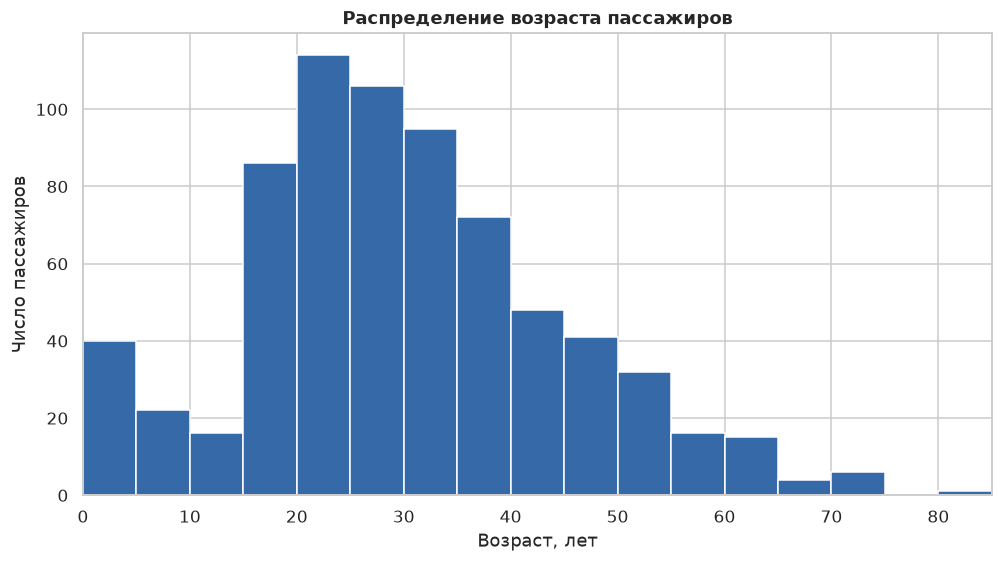

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", font="DejaVu Sans")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
class_colors = ["#3569A8", "#D58135", "#468773"]
survival_colors = ["#B95656", "#368573"]

fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
ax.hist(known_age["Age"], bins=np.arange(0, 86, 5), color=class_colors[0], edgecolor="white")
ax.set(title="Распределение возраста пассажиров", xlabel="Возраст, лет", ylabel="Число пассажиров")
ax.set_xlim(0, 85)
plt.show()

2. Постройте гистограммы распределения цен для пассажиров разных классов

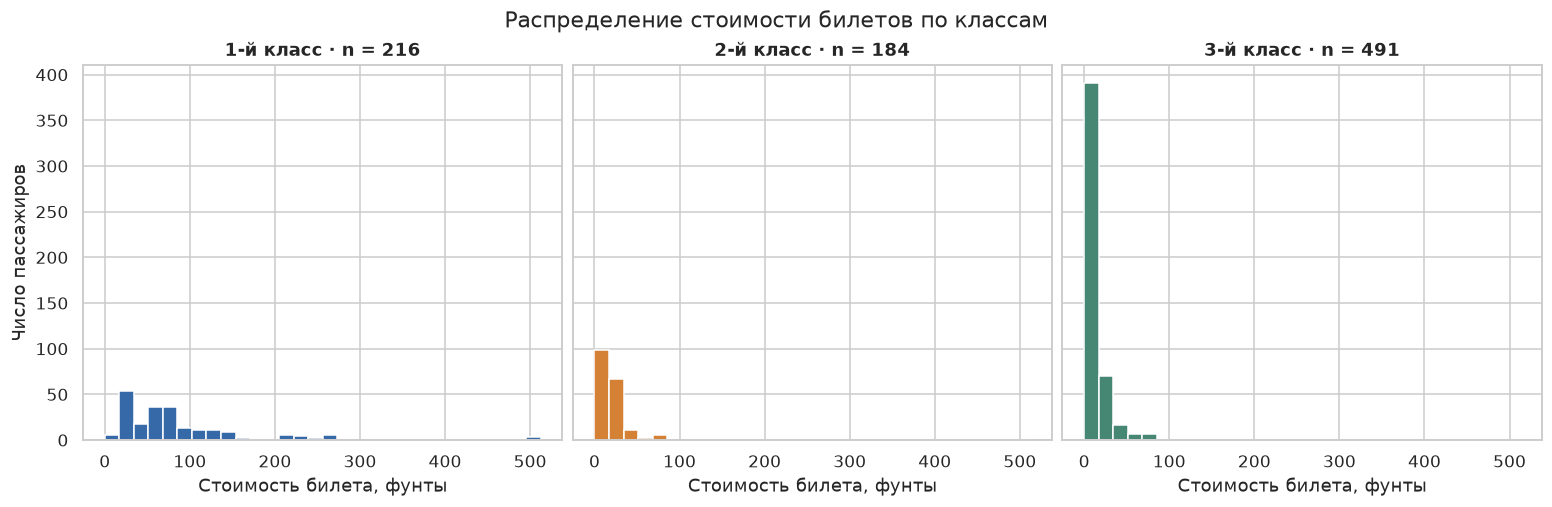

In [ ]:
fare_bins = np.linspace(0, df["Fare"].max(), 31)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharex=True, sharey=True, layout="constrained")
for ax, pclass, color in zip(axes, [1, 2, 3], class_colors):
    fares = df.loc[df["Pclass"] == pclass, "Fare"].dropna()
    ax.hist(fares, bins=fare_bins, color=color, edgecolor="white")
    ax.set(title=f"{pclass}-й класс · n = {len(fares)}", xlabel="Стоимость билета, фунты")
axes[0].set_ylabel("Число пассажиров")
fig.suptitle("Распределение стоимости билетов по классам")
plt.show()

3. Постройте зависимость цены от возраста пассажира

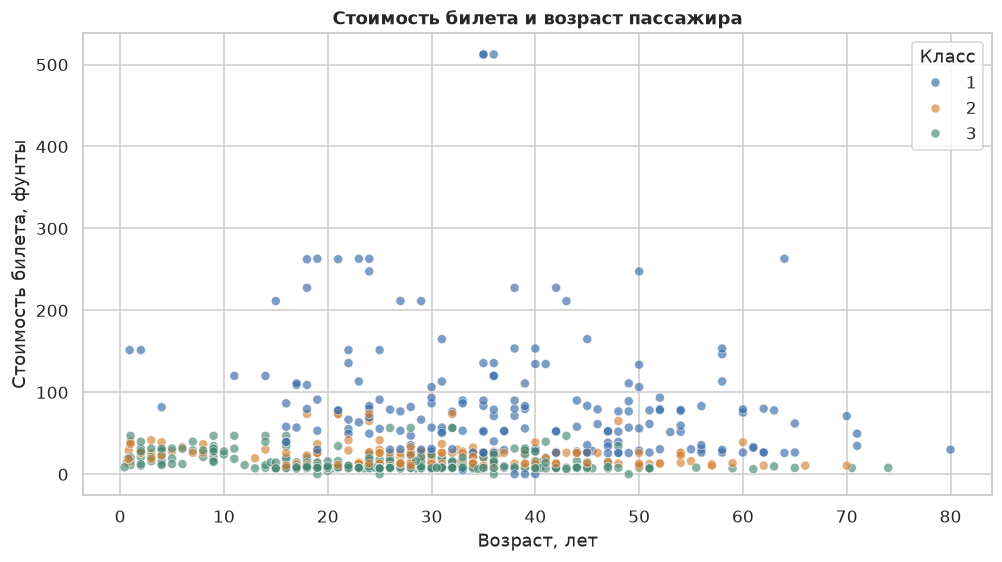

In [26]:
fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
sns.scatterplot(
    data=known_age, x="Age", y="Fare", hue="Pclass", hue_order=[1, 2, 3],
    palette=class_colors, alpha=0.65, s=35, ax=ax
)
ax.set(title="Стоимость билета и возраст пассажира", xlabel="Возраст, лет", ylabel="Стоимость билета, фунты")
ax.legend(title="Класс")
plt.show()

4. Постройте box plot отображающий распределение цен на билеты в разных классах

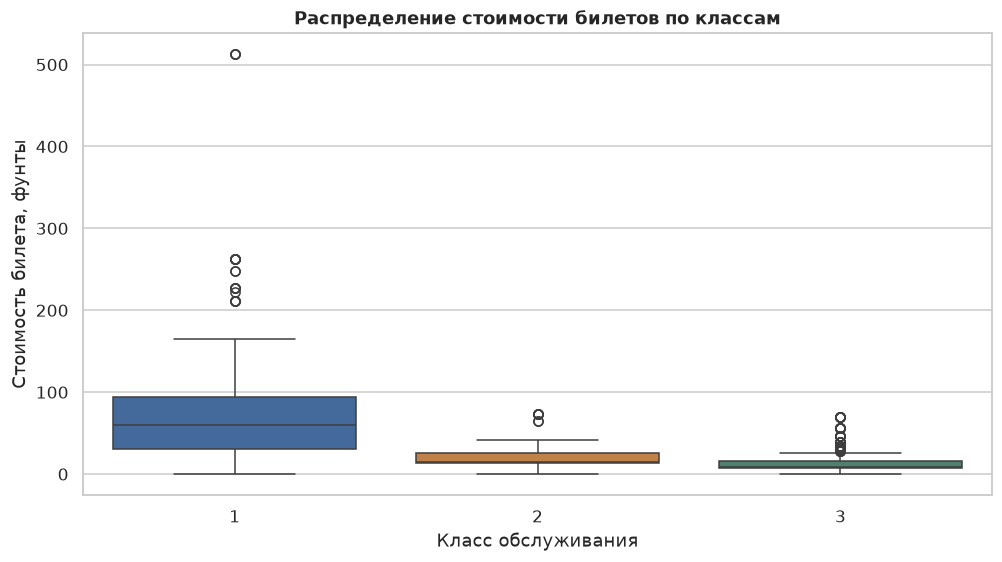

In [27]:
fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
sns.boxplot(
    data=df, x="Pclass", y="Fare", order=[1, 2, 3], hue="Pclass",
    palette=class_colors, legend=False, ax=ax
)
ax.set(title="Распределение стоимости билетов по классам", xlabel="Класс обслуживания", ylabel="Стоимость билета, фунты")
plt.show()

5. Визуализируйте распределение долей выживших среди мужчин, женщин и детей(до 16 лет)

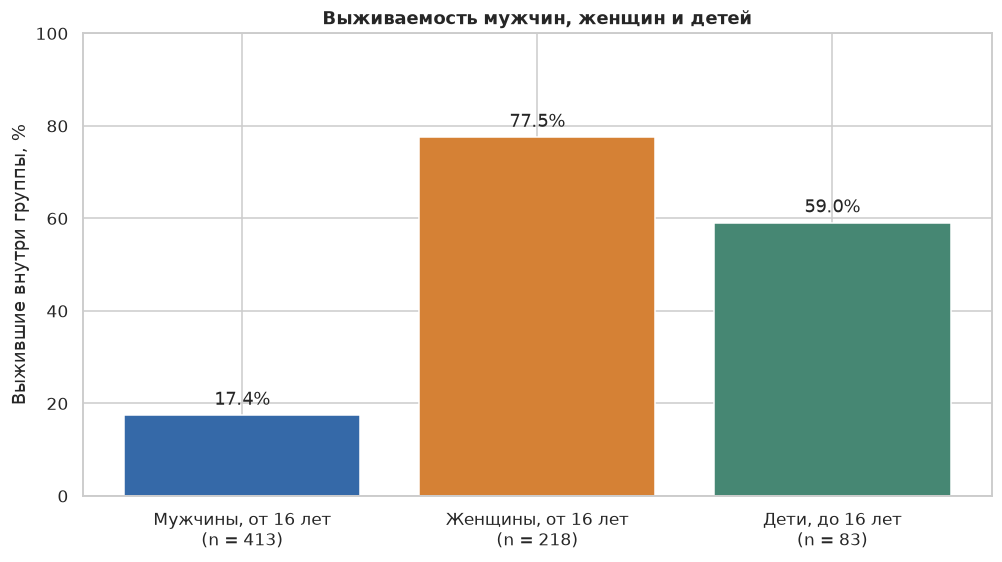

In [28]:
fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
bars = ax.bar(group_order, group_survival["Выживаемость, %"], color=class_colors)
ax.bar_label(bars, labels=[f"{value:.1f}%" for value in group_survival["Выживаемость, %"]], padding=4)
ax.set(ylim=(0, 100), title="Выживаемость мужчин, женщин и детей", ylabel="Выжившие внутри группы, %")
ax.set_xticks(range(3), [
    f"Мужчины, от 16 лет\n(n = {group_survival.loc['Мужчины', 'Пассажиров']})",
    f"Женщины, от 16 лет\n(n = {group_survival.loc['Женщины', 'Пассажиров']})",
    f"Дети, до 16 лет\n(n = {group_survival.loc['Дети', 'Пассажиров']})",
])
plt.show()

Доли рассчитаны **внутри каждой группы**. Группы не пересекаются:
дети обоих полов младше 16 лет, мужчины и женщины от 16 лет;
177 записей без возраста исключены из всех трёх групп.

6. Сравните плотности распределения возростов выживших и умерших пассажиров, сделайте выводы

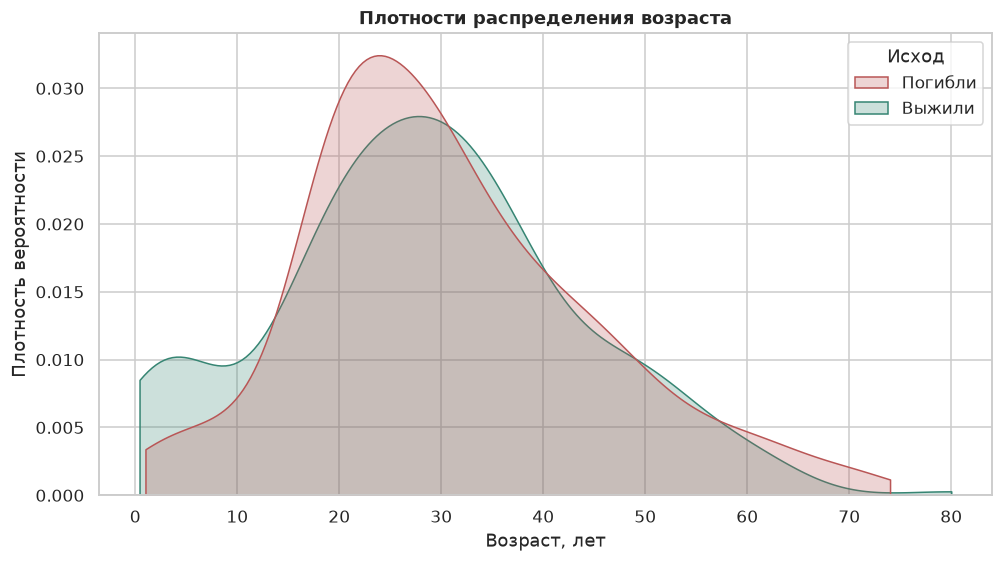

In [29]:
fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
sns.kdeplot(
    data=known_age, x="Age", hue="Survived", hue_order=[0, 1],
    palette=survival_colors, common_norm=False, fill=True, alpha=0.25,
    cut=0, clip=(0, None), ax=ax
)
ax.set(title="Плотности распределения возраста", xlabel="Возраст, лет", ylabel="Плотность вероятности")
legend = ax.get_legend()
legend.set_title("Исход")
for text, label in zip(legend.get_texts(), ["Погибли", "Выжили"]):
    text.set_text(label)
plt.show()

**Вывод:** основные пики обеих плотностей приходятся на молодых взрослых;
распределения существенно перекрываются. Среди выживших заметнее доля
маленьких детей, что согласуется с более высокой выживаемостью детей
(59,04% против 38,19% у взрослых). Каждая плотность нормирована отдельно
до площади 1: высота кривой показывает относительную частоту возраста
внутри группы исхода, а не вероятность выжить в этом возрасте.

7. Постройте круговую диаграмму отображающую выживаемость мужчин и женщин в разных классах обслуживания(визуализация должна быть интуитивно понятная без объяснений, женщины и мужчины соответствующих классов объеденены визуально в одну группу и 2 подгруппы)*

\* Задание на доп. балл

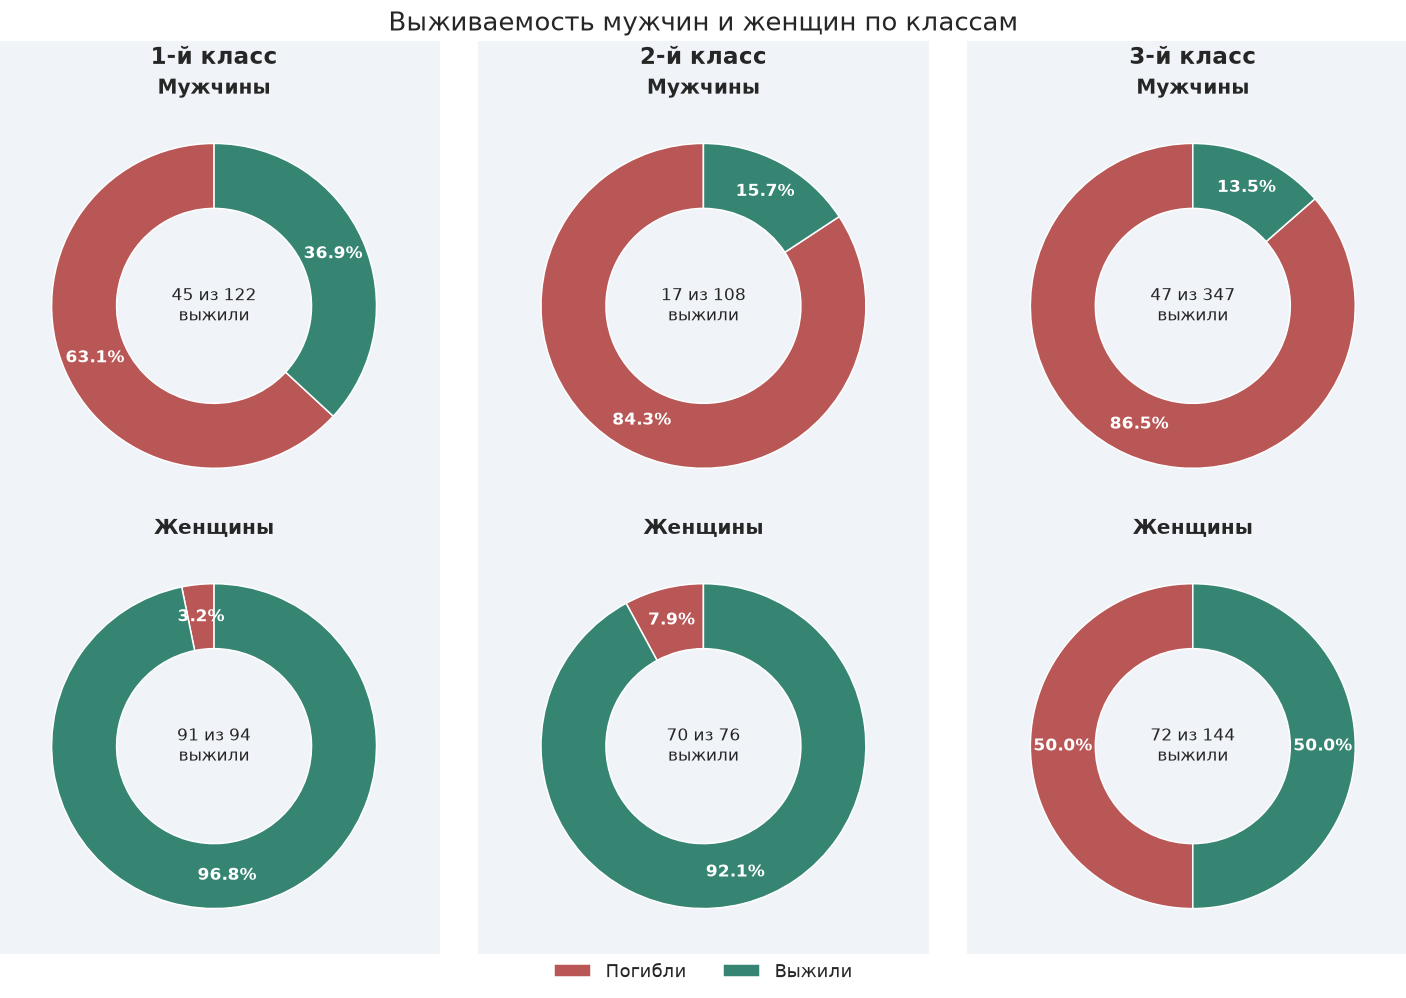

In [ ]:
from matplotlib.patches import Patch


fig = plt.figure(figsize=(13, 9), layout="constrained")
class_panels = fig.subfigures(1, 3, wspace=0.08)
fig.suptitle("Выживаемость мужчин и женщин по классам", fontsize=17)
for panel, pclass in zip(class_panels, [1, 2, 3]):
    panel.set_facecolor("#F0F3F7")
    panel.suptitle(f"{pclass}-й класс", fontsize=15, fontweight="bold")
    axes = panel.subplots(2, 1)
    for ax, sex, label in zip(axes, ["male", "female"], ["Мужчины", "Женщины"]):
        passengers = df.loc[(df["Pclass"] == pclass) & (df["Sex"] == sex), "Survived"]
        survivors = int(passengers.sum())
        counts = [len(passengers) - survivors, survivors]
        ax.pie(
            counts, colors=survival_colors, startangle=90,
            autopct="%1.1f%%", pctdistance=0.80,
            wedgeprops={"width": 0.40, "edgecolor": "white"},
            textprops={"color": "white", "fontsize": 11, "fontweight": "bold"},
        )
        ax.text(0, 0, f"{survivors} из {len(passengers)}\nвыжили", ha="center", va="center", fontsize=11)
        ax.set_title(label, fontsize=13)
fig.legend(
    handles=[Patch(facecolor=color, label=label) for color, label in zip(survival_colors, ["Погибли", "Выжили"])],
    loc="outside lower center", ncol=2, frameon=False, fontsize=12,
)
plt.show()